SVO detector convention: JWST/MIRI, JWST/NIRSpec and Spitzer/IRAC are all photon counters (tabulated T(lambda) is electrons per incident photon).

SPIDERMAN's get_filter multiplies by hc/lambda internally.

In [1]:
import glob
import os
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import fspiderman as sp
from astro_utils import *
from hyperillumination_phasecurve_utils import *
from HItargets_utils import *

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
FILTER_DIR  = "raw SVO"
OUT_DIR     = "Spiderman"
PANDEIA_CFG = "raw Pandeira/pandeia_data-2026.7-jwst/jwst/nirspec/config.json"
# Data downloaded from http://svo2.cab.inta-csic.es/theory/fps

#### G395H Split

In [3]:
# NIRSpec G395H is dispersed across two detectors, NRS1 and NRS2.
# SVO tabulates optical transmission only (components: "Filter + CCD + Instrument"), so its single G395H_F290LP curve runs smoothly across the detector gap: photons at 3.72-3.82 um pass the F290LP filter and the G395H grating perfectly well, they just land in the physical space between the two H2RG arrays and are never recorded. 
# The gap is detector geometry, not throughput, so it has to be imposed by hand -- Pandeia's get_total_eff is blind to it for the same reason.


G395H_FALLBACK = {"wave_min": 2.87, "gap_start": 3.71934, "gap_end": 3.823, "wave_max": 5.17692}

def g395h_edges(cfg_path=PANDEIA_CFG, aperture="s1600a1", subarray="default"):
    """NRS1/NRS2 gap and spectral extent in microns, from the local Pandeia reference data."""
    try:
        with open(cfg_path) as fh:
            return json.load(fh)["slit_config"][aperture]["gap"][subarray]["g395h"]
    except (OSError, KeyError):
        print("Pandeia config not found -- falling back to hard-coded s1600a1 values")
        return G395H_FALLBACK

g395h = g395h_edges()
print({k: g395h[k] for k in ("wave_min", "gap_start", "gap_end", "wave_max")})

SPLITS = {
    "JWST_NIRSpec.G395H_F290LP": {
        "JWST_NIRSpec.G395H_NRS1": (g395h["wave_min"], g395h["gap_start"]),
        "JWST_NIRSpec.G395H_NRS2": (g395h["gap_end"],  g395h["wave_max"]),
    },
}

{'wave_min': 2.87, 'gap_start': 3.71934, 'gap_end': 3.823, 'wave_max': 5.17692}


### Convert SVO ASCII (Angstrom, transmission) -> SPIDERMAN filter file (metres, photon response)

In [4]:
# SPIDERMAN's spiderman.web.get_filter parses with line.strip('\\n').split(' '), so the file must be
# single-space separated with no header, no comments and no blank lines.

def _insert_nodes(w, T, nodes):
    """Insert exact wavelength nodes (metres) into the tabulated curve by linear interpolation, so a
    window edge sits exactly at the requested wavelength rather than on the nearest tabulated point
    (the SVO G395H grid is ~4.6 nm)."""
    nodes = np.asarray([x for x in np.atleast_1d(nodes) if w[0] < x < w[-1]], dtype=float)
    if nodes.size == 0:
        return w, T
    w2 = np.concatenate([w, nodes])
    T2 = np.concatenate([T, np.interp(nodes, w, T)])
    w2, idx = np.unique(w2, return_index=True)   # sorts and drops exact duplicates
    return w2, T2[idx]


def svo_to_spiderman(svo_file, out_file, window=None, thresh=1e-3, pad_frac=0.02):
    w_ang, T = np.loadtxt(svo_file, unpack=True)
    w = w_ang * 1e-10  # Angstrom -> metre



    # restrict to a detector window (microns), with the edges placed exactly
    if window is not None:
        wmin, wmax = window[0] * 1e-6, window[1] * 1e-6
        w, T = _insert_nodes(w, T, [wmin, wmax])
        m = (w >= wmin) & (w <= wmax)
        w, T = w[m], T[m]

    # drop the far wings
    keep = T > thresh * T.max()
    i0, i1 = np.argmax(keep), len(keep) - np.argmax(keep[::-1])
    w, T = w[i0:i1], T[i0:i1]

    # Zero padding outside band
    dw = pad_frac * (w[-1] - w[0])
    w = np.concatenate(([w[0] - dw], w, [w[-1] + dw]))
    T = np.concatenate(([0.0], T, [0.0]))

    # Pre-compensate SPIDERMAN's inverted lambda factor (web.py:get_filter applies hc/lambda where a counts/photon response needs lambda/hc). Writing T*lambda^2 makes its internal weight come out as R*lambda.
    # WARNING: the file is then NOT a throughput. Divide by lambda^2 to recover one (or call *.throughput.dat)
    np.savetxt(out_file, np.c_[w, T * (w*1e6)**2], fmt="%.10e %.10e")
    return w, T


def band_properties(w, T):
    # Pivot wavelength (characteristic wavelength where the band sits) and 50%/1% edges, all in metres.
    lpiv = np.sqrt(np.trapezoid(T * w, w) / np.trapezoid(T / w, w))
    def edges(frac):
        m = T >= frac * T.max()
        return w[m][0], w[m][-1]
    return lpiv, edges(0.5), edges(0.01)


filters = {}
for f in sorted(glob.glob(os.path.join(FILTER_DIR, "*.dat"))):
    name = os.path.splitext(os.path.basename(f))[0]
    for out_name, window in SPLITS.get(name, {name: None}).items():
        out  = os.path.join(OUT_DIR, out_name + ".spiderman.dat")
        w, T = svo_to_spiderman(f, out, window=window)
        lpiv, e50, e01 = band_properties(w, T)
        filters[out_name] = dict(path=out, w=w, T=T, l1=w[0], l2=w[-1],
                                 lpiv=lpiv, e50=e50, e01=e01, window=window)

In [5]:
um = 1e6
print(f"{'filter':26s} {'l1 [um]':>9s} {'l2 [um]':>9s} {'pivot':>8s} "
      f"{'50% edges [um]':>20s} {'1% edges [um]':>20s}")
print("-" * 99)
for n, d in filters.items():
    print(f"{n:26s} {d['l1']*um:9.4f} {d['l2']*um:9.4f} {d['lpiv']*um:8.4f} "
          f"{d['e50'][0]*um:9.4f}-{d['e50'][1]*um:<9.4f} "
          f"{d['e01'][0]*um:9.4f}-{d['e01'][1]*um:<9.4f}")

filter                       l1 [um]   l2 [um]    pivot       50% edges [um]        1% edges [um]
---------------------------------------------------------------------------------------------------
JWST_MIRI.F1280W             11.0654   14.5816  12.8101   11.5910-14.1200     11.2540-14.3340  
JWST_MIRI.F1500W             12.7875   17.4925  15.0635   13.5280-16.6370     13.1220-17.1410  
JWST_MIRI.F1800W             15.5725   20.8505  17.9839   16.5210-19.4960     16.0280-20.2850  
JWST_NIRSpec.G395H_NRS1       2.8530    3.7363   3.3240    2.8839-3.7193       2.8700-3.7193   
JWST_NIRSpec.G395H_NRS2       3.7959    5.2040   4.4147    3.8230-5.1769       3.8230-5.1769   
Spitzer_IRAC.I2               3.6955    5.1008   4.4959    3.9980-5.0052       3.9194-5.0540   


### Plotting the SVO Throughputs

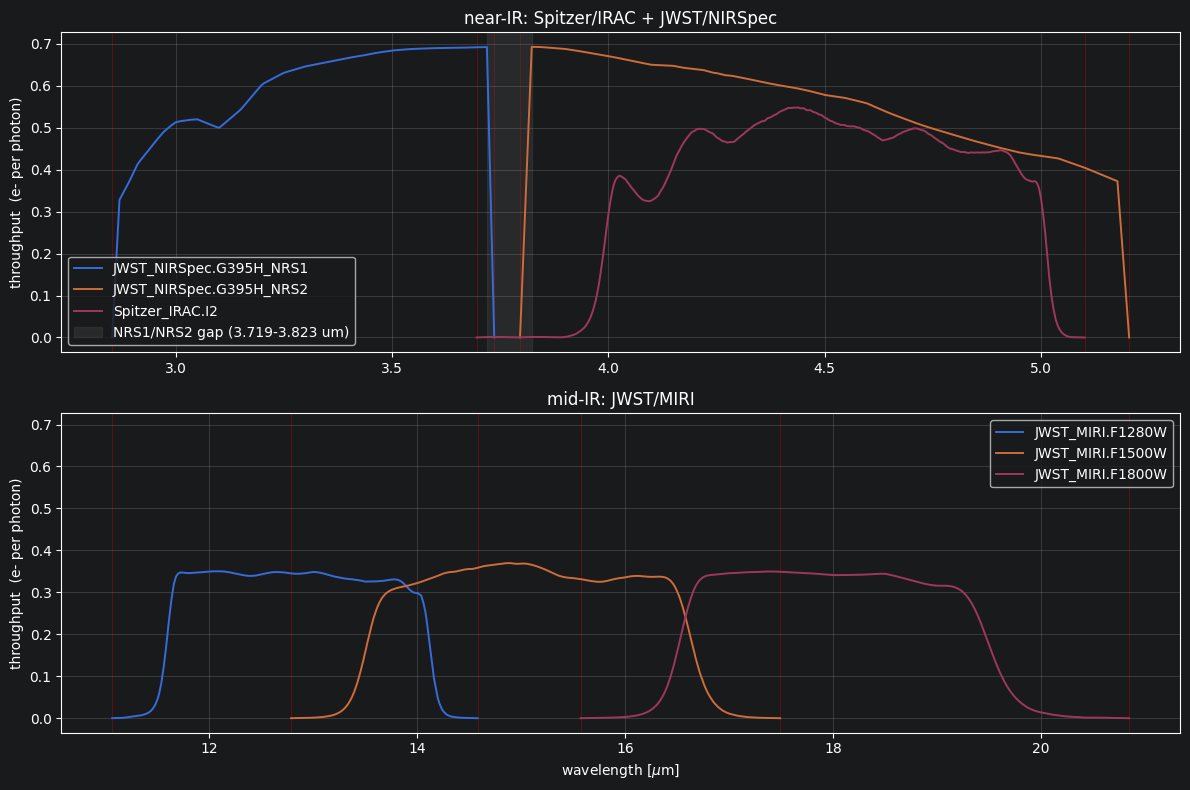

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
for n, d in filters.items():
    ax = axes[0] if d["lpiv"] < 8e-6 else axes[1]
    ax.plot(d["w"] * um, d["T"], lw=1.4, label=n)
    ax.axvline(d["l1"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)
    ax.axvline(d["l2"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)

# the NRS1/NRS2 gap: fully transmitted by the optics, never recorded by a detector
axes[0].axvspan(g395h["gap_start"], g395h["gap_end"], color="0.4", alpha=0.2, zorder=0,
                label=f"NRS1/NRS2 gap ({g395h['gap_start']:.3f}-{g395h['gap_end']:.3f} um)")

for ax, ttl in zip(axes, ["near-IR: Spitzer/IRAC + JWST/NIRSpec", "mid-IR: JWST/MIRI"]):
    ax.set_ylabel("throughput  (e- per photon)")
    ax.set_title(ttl); ax.grid(alpha=.3); ax.legend()
axes[1].set_xlabel(f"wavelength [$\\mu$m]")
fig.tight_layout()

### Applied to thermal PhaseCurve model (Spiderman)

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


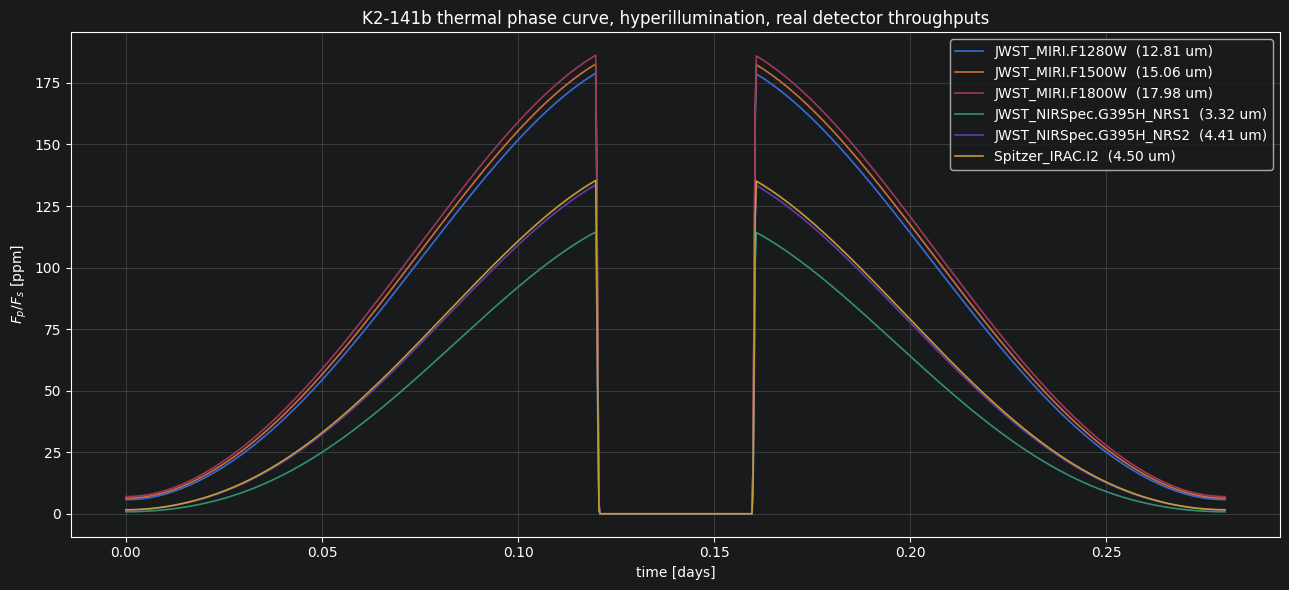

In [7]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = K2_141b.args

fp = 142e-6                                 # planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer's IRAC Channel 2 at 4.5 um

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer's IRAC Channel 2 at 4.5 um
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!


filter_notes = {
    "JWST_MIRI.F1280W":        "MIRI imaging TSO. Below the CO2 band, can check a CO2 atmosphere (combined with F1500W)",
    "JWST_MIRI.F1500W":        "MIRI imaging TSO. Used on TRAPPIST (15um CO2 band), good for a cold nightside",
    "JWST_MIRI.F1800W":        "MIRI imaging TSO. MIRI's thermal background climbs steeply past ~15um",
    "Spitzer_IRAC.I2":         "~Spitzer IRAC channel 2 (4.5um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)",
    "JWST_NIRSpec.G395H_NRS1": "NIRSpec BOTS, blue detector (2.87-3.72um). Same regime as IRAC2 but resolved",
    "JWST_NIRSpec.G395H_NRS2": "NIRSpec BOTS, red detector (3.82-5.18um). Fitted independently of NRS1 (inter-detector offset ~40-50 ppm)",
}
filter_paths = {n: d["path"] for n, d in filters.items()}


def thermal_model(l1, l2, insolation_model="hyperillum", filter_path=False, n_lo=200, n_la=100, n_layers=50):
    lo, la, Tg = custom_temperature_grid(K2_141b, n_lo=n_lo, n_la=n_la, insolation_model=insolation_model, A_B=A_B, u_B=u_B)
    T_floor = 100.

    LO, LA = np.meshgrid(lo, la, indexing="ij")

    p = sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody")
    p.n_layers = n_layers
    p.t0, p.per = 0.0, period
    p.a_abs = a_AU
    p.inc, p.ecc, p.w = incl, ecc, w
    p.rp, p.a = rp, a
    p.p_u1 = p.p_u2 = 0.0
    p.T_s  = T_eff
    p.grid = sp.format_grid(LO, LA, np.maximum(Tg, T_floor).T)
    p.l1, p.l2 = l1, l2
    p.filter = filter_path            # False -> top-hat over [l1, l2]
    return p

# phase curves in every band
t = np.linspace(0, period, 1000)
fig, ax = plt.subplots(figsize=(13, 6))

for n, d in filters.items():
    sg = sp.stellar_grid.gen_grid(d["l1"], d["l2"], logg=4.5, response=d["path"])
    p  = thermal_model(d["l1"], d["l2"], "hyperillum", d["path"])
    ax.plot(t, (fast_lightcurve(p, sg, t) - 1) * 1e6, lw=1.2, label=f"{n}  ({d['lpiv']*um:.2f} um)")

ax.set_xlabel("time [days]"); ax.set_ylabel(r"$F_p/F_s$ [ppm]")
ax.set_title("K2-141b thermal phase curve, hyperillumination, real detector throughputs")
ax.legend()
ax.grid(alpha=.3)
fig.tight_layout()